# **VISUALIZATION OTUPUT 3D**

## **UNET3D**

### FUNCTION

**Start slice** → first slice where pancreas area ≥ 20% of the maximum \
**Central slice** → slice at the midpoint among all slices containing pancreas (NOT the one with maximum area) \
**End slice** → last slice where pancreas area ≥ 20% of the maximum

In [26]:
import numpy as np
import SimpleITK as sitk
import matplotlib.pyplot as plt
import torch
from pathlib import Path
from monai.inferers import sliding_window_inference


@torch.no_grad()
def show_prediction_patient_3d_3slices(
    model,
    ct_dir,
    mask_dir,
    patient_id: str,
    threshold: float = 0.5,
    alpha: float = 0.35,
    window: tuple | None = None,   
    device: torch.device | str = "cuda",
    area_ratio: float = 0.20,
    roi_size: tuple = (96, 96, 96),
    sw_batch_size: int = 1,
):
    if isinstance(device, str):
        if device == "cuda" and not torch.cuda.is_available():
            print("CUDA is not available. Falling back to CPU.")
            device = torch.device("cpu")
        else:
            device = torch.device(device)

    model = model.to(device)
    model.eval()

    ct_path = Path(ct_dir) / f"pancreas_{patient_id}.nii.gz"
    m_path = Path(mask_dir) / f"label{patient_id}.nii.gz"

    ct = sitk.GetArrayFromImage(sitk.ReadImage(str(ct_path))).astype(np.float32)   # (Z,Y,X)
    gt = sitk.GetArrayFromImage(sitk.ReadImage(str(m_path))).astype(np.uint8)      # (Z,Y,X)

    # ----- slice selection from GT -----
    areas = gt.reshape(gt.shape[0], -1).sum(axis=1)
    pos = np.where(areas > 0)[0]

    if len(pos) == 0:
        print(f"No pancreas found in ground truth for patient {patient_id}.")
        return

    central_idx = int(pos[len(pos) // 2])

    max_area = areas[pos].max()
    area_thr = area_ratio * max_area
    significant_pos = pos[areas[pos] >= area_thr]

    if len(significant_pos) >= 2:
        first_idx = int(significant_pos[0])
        last_idx = int(significant_pos[-1])
    else:
        first_idx = int(pos[0])
        last_idx = int(pos[-1])

    selected_slices = [first_idx, central_idx, last_idx]
    row_titles = ["Pancreas start", "Central slice", "Pancreas end"]

    # ----- same normalization style used in training -----
    ct_norm = ct.copy()
    mean = ct_norm.mean()
    std = ct_norm.std()
    if std > 0:
        ct_norm = (ct_norm - mean) / std
    else:
        ct_norm = ct_norm - mean

    # ----- 3D inference with sliding window -----
    x = torch.from_numpy(ct_norm[None, None, ...]).float().to(device)   # (1,1,Z,Y,X)

    logits = sliding_window_inference(
        inputs=x,
        roi_size=roi_size,
        sw_batch_size=sw_batch_size,
        predictor=model,
    )

    if logits.ndim != 5:
        raise ValueError(f"Unexpected model output shape: {tuple(logits.shape)}")

    if logits.shape[1] == 1:
        prob = torch.sigmoid(logits)[0, 0].cpu().numpy()   # (Z,Y,X)
    else:
        raise ValueError("This function expects binary segmentation with one output channel.")

    pred = (prob >= threshold).astype(np.uint8)

    # ----- plot -----
    fig, axes = plt.subplots(3, 3, figsize=(12, 12))
    summary = []

    for r, z in enumerate(selected_slices):
        img = ct[z]   # original CT for display
        gt2d = (gt[z] > 0).astype(np.uint8)
        pred2d = pred[z]
        prob2d = prob[z]

        disp = img.copy()
        if window is not None:
            lo, hi = window
            disp = np.clip(disp, lo, hi)

        axes[r, 0].imshow(disp, cmap="gray")
        axes[r, 0].set_title(f"{row_titles[r]} | z={z}")
        axes[r, 0].axis("off")

        axes[r, 1].imshow(disp, cmap="gray")
        axes[r, 1].imshow(gt2d, cmap="Reds", alpha=alpha, vmin=0, vmax=1, interpolation="nearest")
        axes[r, 1].set_title("Ground Truth")
        axes[r, 1].axis("off")

        axes[r, 2].imshow(disp, cmap="gray")
        axes[r, 2].imshow(pred2d, cmap="Blues", alpha=alpha, vmin=0, vmax=1, interpolation="nearest")
        axes[r, 2].set_title(f"Prediction (thr={threshold})")
        axes[r, 2].axis("off")

        summary.append({
            "slice": z,
            "gt_pixels": int(gt2d.sum()),
            "pred_pixels": int(pred2d.sum()),
            "prob_min": float(prob2d.min()),
            "prob_max": float(prob2d.max()),
        })

    plt.suptitle(f"Patient {patient_id} - Original / GT / Prediction", fontsize=16)
    plt.tight_layout()
    plt.show()

    print(f"\nPatient {patient_id}")
    print(f"Selected slices: start={first_idx}, center={central_idx}, end={last_idx}")
    print(f"Significant area threshold: {area_thr:.2f} pixels ({area_ratio*100:.0f}% of max area)")
    print(f"Sliding window ROI size: {roi_size}\n")

    for i, s in enumerate(summary):
        print(
            f"{row_titles[i]} | z={s['slice']} | "
            f"GT pixels={s['gt_pixels']} | Pred pixels={s['pred_pixels']} | "
            f"prob min/max=({s['prob_min']:.4f}, {s['prob_max']:.4f})"
        )

### FIRST TRIAL 

We have discard it because it produced really poor results

### SECOND TRIAL 

In [27]:
import torch
from monai.networks.nets import UNet

device = "cpu"   

ckpt_path = r"C:\Users\pietr\Desktop\Visualizzazione otuput 3d\models 3d\second unet3d\baseline_best_model.pt"

state_dict = torch.load(ckpt_path, map_location=device)

model3d = UNet(
    spatial_dims=3,
    in_channels=1,
    out_channels=1,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    num_res_units=2,
).to(device)

model3d.load_state_dict(state_dict)
model3d.eval()

print("Loaded MONAI 3D UNet from:", ckpt_path)

Loaded MONAI 3D UNet from: C:\Users\pietr\Desktop\Visualizzazione otuput 3d\models 3d\second unet3d\baseline_best_model.pt


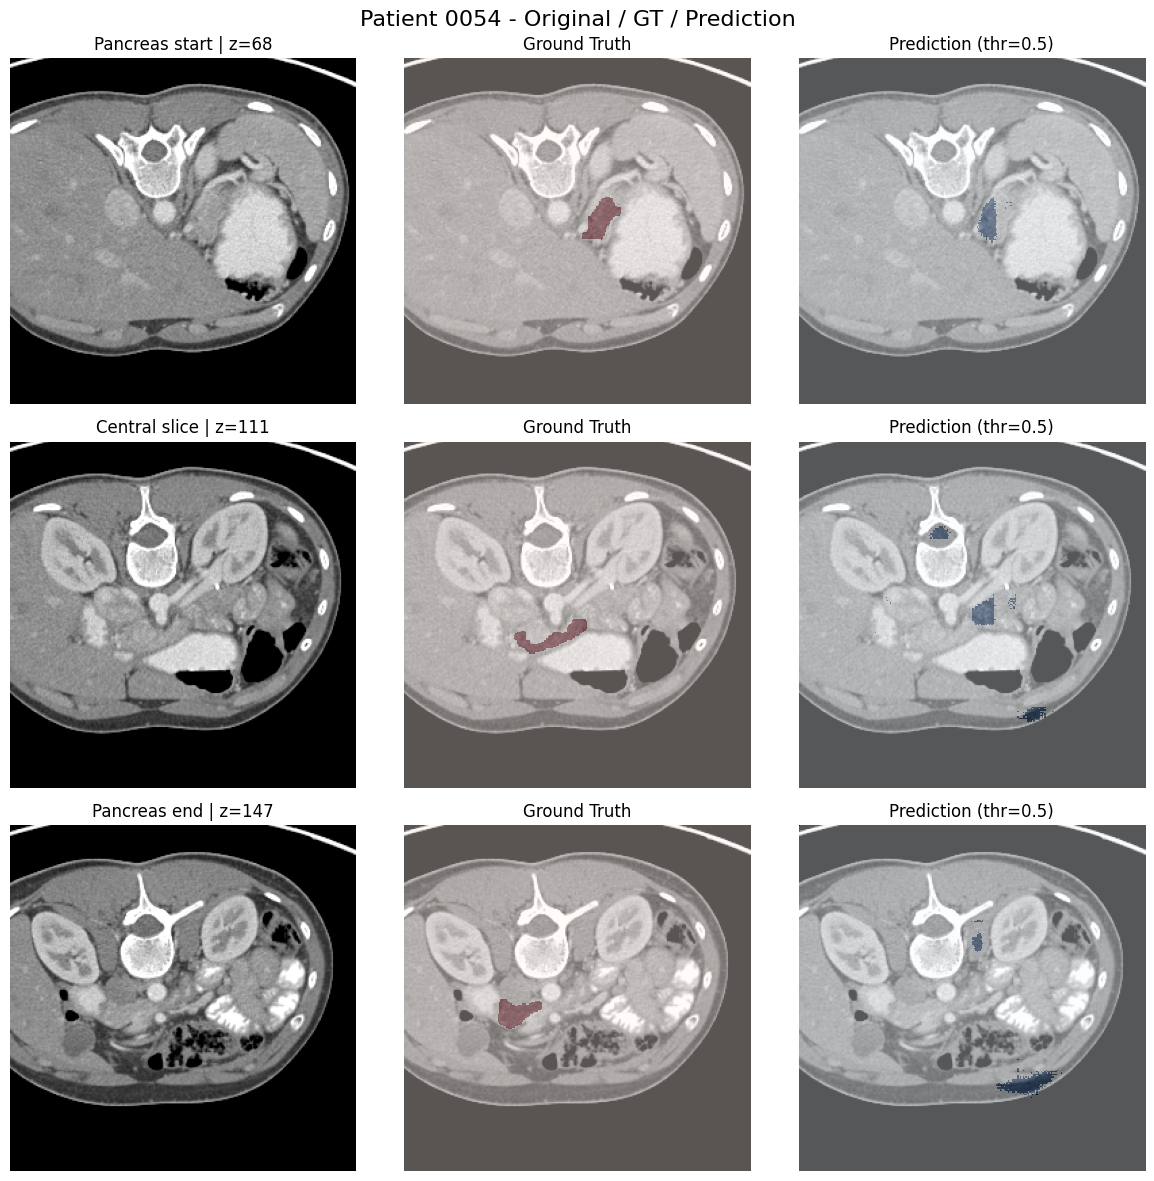


Patient 0054
Selected slices: start=68, center=111, end=147
Significant area threshold: 402.40 pixels (20% of max area)
Sliding window ROI size: (96, 96, 96)

Pancreas start | z=68 | GT pixels=474 | Pred pixels=302 | prob min/max=(0.1001, 0.7314)
Central slice | z=111 | GT pixels=505 | Pred pixels=522 | prob min/max=(0.0697, 0.6708)
Pancreas end | z=147 | GT pixels=438 | Pred pixels=484 | prob min/max=(0.0647, 0.6495)


In [28]:
show_prediction_patient_3d_3slices(
    model=model3d,
    ct_dir=r"C:\Users\pietr\Desktop\Visualizzazione otuput 3d\dataset_split_1303\test\ct",
    mask_dir=r"C:\Users\pietr\Desktop\Visualizzazione otuput 3d\dataset_split_1303\test\mask",
    patient_id="0054",
    threshold=0.5,
    alpha=0.35,
    window=(-100,200),
    device="cpu",
    area_ratio=0.20
)

## **SwinUNETR**

### FUNCTION 

In [16]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import SimpleITK as sitk
from pathlib import Path
from matplotlib.colors import ListedColormap
from monai.inferers import sliding_window_inference


@torch.no_grad()
def show_prediction_patient_3d_3slices_swin(
    model,
    ct_dir,
    mask_dir,
    patient_id: str,
    threshold: float = 0.5,
    alpha: float = 0.35,
    window: tuple = (-100, 200),
    device: torch.device | str = "cuda",
    area_ratio: float = 0.20,
    roi_size: tuple = (96, 96, 96),
    sw_batch_size: int = 1,
    overlap: float = 0.5,
):
    if isinstance(device, str):
        device = torch.device(device)

    model = model.to(device)
    model.eval()

    cmap_gt = ListedColormap(["none", "red"])
    cmap_pred = ListedColormap(["none", "blue"])

    ct_path = Path(ct_dir) / f"pancreas_{patient_id}.nii.gz"
    m_path = Path(mask_dir) / f"label{patient_id}.nii.gz"

    if not ct_path.exists():
        print(f"CT file not found: {ct_path}")
        return
    if not m_path.exists():
        print(f"Mask file not found: {m_path}")
        return

    # Read volumes (Z, Y, X)
    ct_np = sitk.GetArrayFromImage(sitk.ReadImage(str(ct_path))).astype(np.float32)
    gt_np = sitk.GetArrayFromImage(sitk.ReadImage(str(m_path))).astype(np.uint8)

    # Full-volume inference exactly like in your working function
    input_tensor = torch.from_numpy(ct_np)[None, None, ...].to(device)

    logits = sliding_window_inference(
        inputs=input_tensor,
        roi_size=roi_size,
        sw_batch_size=sw_batch_size,
        predictor=model,
        overlap=overlap,
    )

    probs = torch.sigmoid(logits)[0, 0].cpu().numpy()
    pred_np = (probs >= threshold).astype(np.uint8)

    # ----- slice selection logic -----
    gt_sums = gt_np.sum(axis=(1, 2))
    slices_with_organ = np.where(gt_sums > 0)[0]

    if len(slices_with_organ) == 0:
        print(f"Warning: pancreas not present in GT for patient {patient_id}.")
        first_idx = 0
        central_idx = ct_np.shape[0] // 2
        last_idx = ct_np.shape[0] - 1
    else:
        central_idx = int(len(slices_with_organ) // 2)
        central_idx = int(slices_with_organ[central_idx])

        max_area = gt_sums[slices_with_organ].max()
        area_thr = area_ratio * max_area

        significant_slices = slices_with_organ[gt_sums[slices_with_organ] >= area_thr]

        if len(significant_slices) >= 2:
            first_idx = int(significant_slices[0])
            last_idx = int(significant_slices[-1])
        else:
            first_idx = int(slices_with_organ[0])
            last_idx = int(slices_with_organ[-1])

    selected_slices = [first_idx, central_idx, last_idx]
    row_titles = ["Pancreas start", "Central slice", "Pancreas end"]

    # Volumetric Dice
    dice_vol = (2.0 * (pred_np * gt_np).sum()) / (pred_np.sum() + gt_np.sum() + 1e-8)

    print(f"\nPatient {patient_id}")
    print(f"Selected slices: start={first_idx}, center={central_idx}, end={last_idx}")
    if len(slices_with_organ) > 0:
        print(f"Pancreas range in GT: {slices_with_organ[0]}-{slices_with_organ[-1]}")
        print(f"Area threshold for start/end: {area_ratio*100:.0f}% of max area")
    print(f"Volumetric Dice: {dice_vol:.4f}")

    # ----- plot -----
    fig, axes = plt.subplots(3, 3, figsize=(18, 15))

    for r, z in enumerate(selected_slices):
        disp_slice = np.clip(ct_np[z], window[0], window[1])
        gt_slice = gt_np[z]
        pred_slice = pred_np[z]

        mask_gt = np.ma.masked_where(gt_slice == 0, gt_slice)
        mask_pred = np.ma.masked_where(pred_slice == 0, pred_slice)

        # 1. CT
        axes[r, 0].imshow(disp_slice, cmap="gray")
        axes[r, 0].set_title(f"{row_titles[r]} | CT | z={z}")
        axes[r, 0].axis("off")

        # 2. GT
        axes[r, 1].imshow(disp_slice, cmap="gray")
        axes[r, 1].imshow(mask_gt, cmap=cmap_gt, alpha=alpha, vmin=0, vmax=1, interpolation="nearest")
        axes[r, 1].set_title(f"{row_titles[r]} | Ground Truth")
        axes[r, 1].axis("off")

        # 3. Prediction
        axes[r, 2].imshow(disp_slice, cmap="gray")
        axes[r, 2].imshow(mask_pred, cmap=cmap_pred, alpha=alpha, vmin=0, vmax=1, interpolation="nearest")
        axes[r, 2].set_title(f"{row_titles[r]} | Prediction")
        axes[r, 2].axis("off")

    plt.suptitle(
        f"Patient {patient_id} - Original / GT / Prediction (Dice Vol: {dice_vol:.3f})",
        fontsize=16
    )
    plt.tight_layout()
    plt.show()

### **FIRST TRIAL**

In [17]:
import torch
from monai.networks.nets import SwinUNETR

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ckpt_path = r"C:\Users\pietr\Desktop\Visualizzazione otuput 3d\models 3d\first swinunetr\best_swinunetr_dice.pt"

model_swin = SwinUNETR(
    in_channels=1,
    out_channels=1,
    feature_size=48,
    use_checkpoint=False,
).to(device)

model_swin.load_state_dict(torch.load(ckpt_path, map_location=device))
model_swin.eval()

print("Loaded SwinUNETR from:", ckpt_path)

Loaded SwinUNETR from: C:\Users\pietr\Desktop\Visualizzazione otuput 3d\models 3d\first swinunetr\best_swinunetr_dice.pt



Patient 0054
Selected slices: start=68, center=111, end=147
Pancreas range in GT: 62-159
Area threshold for start/end: 20% of max area
Volumetric Dice: 0.5988


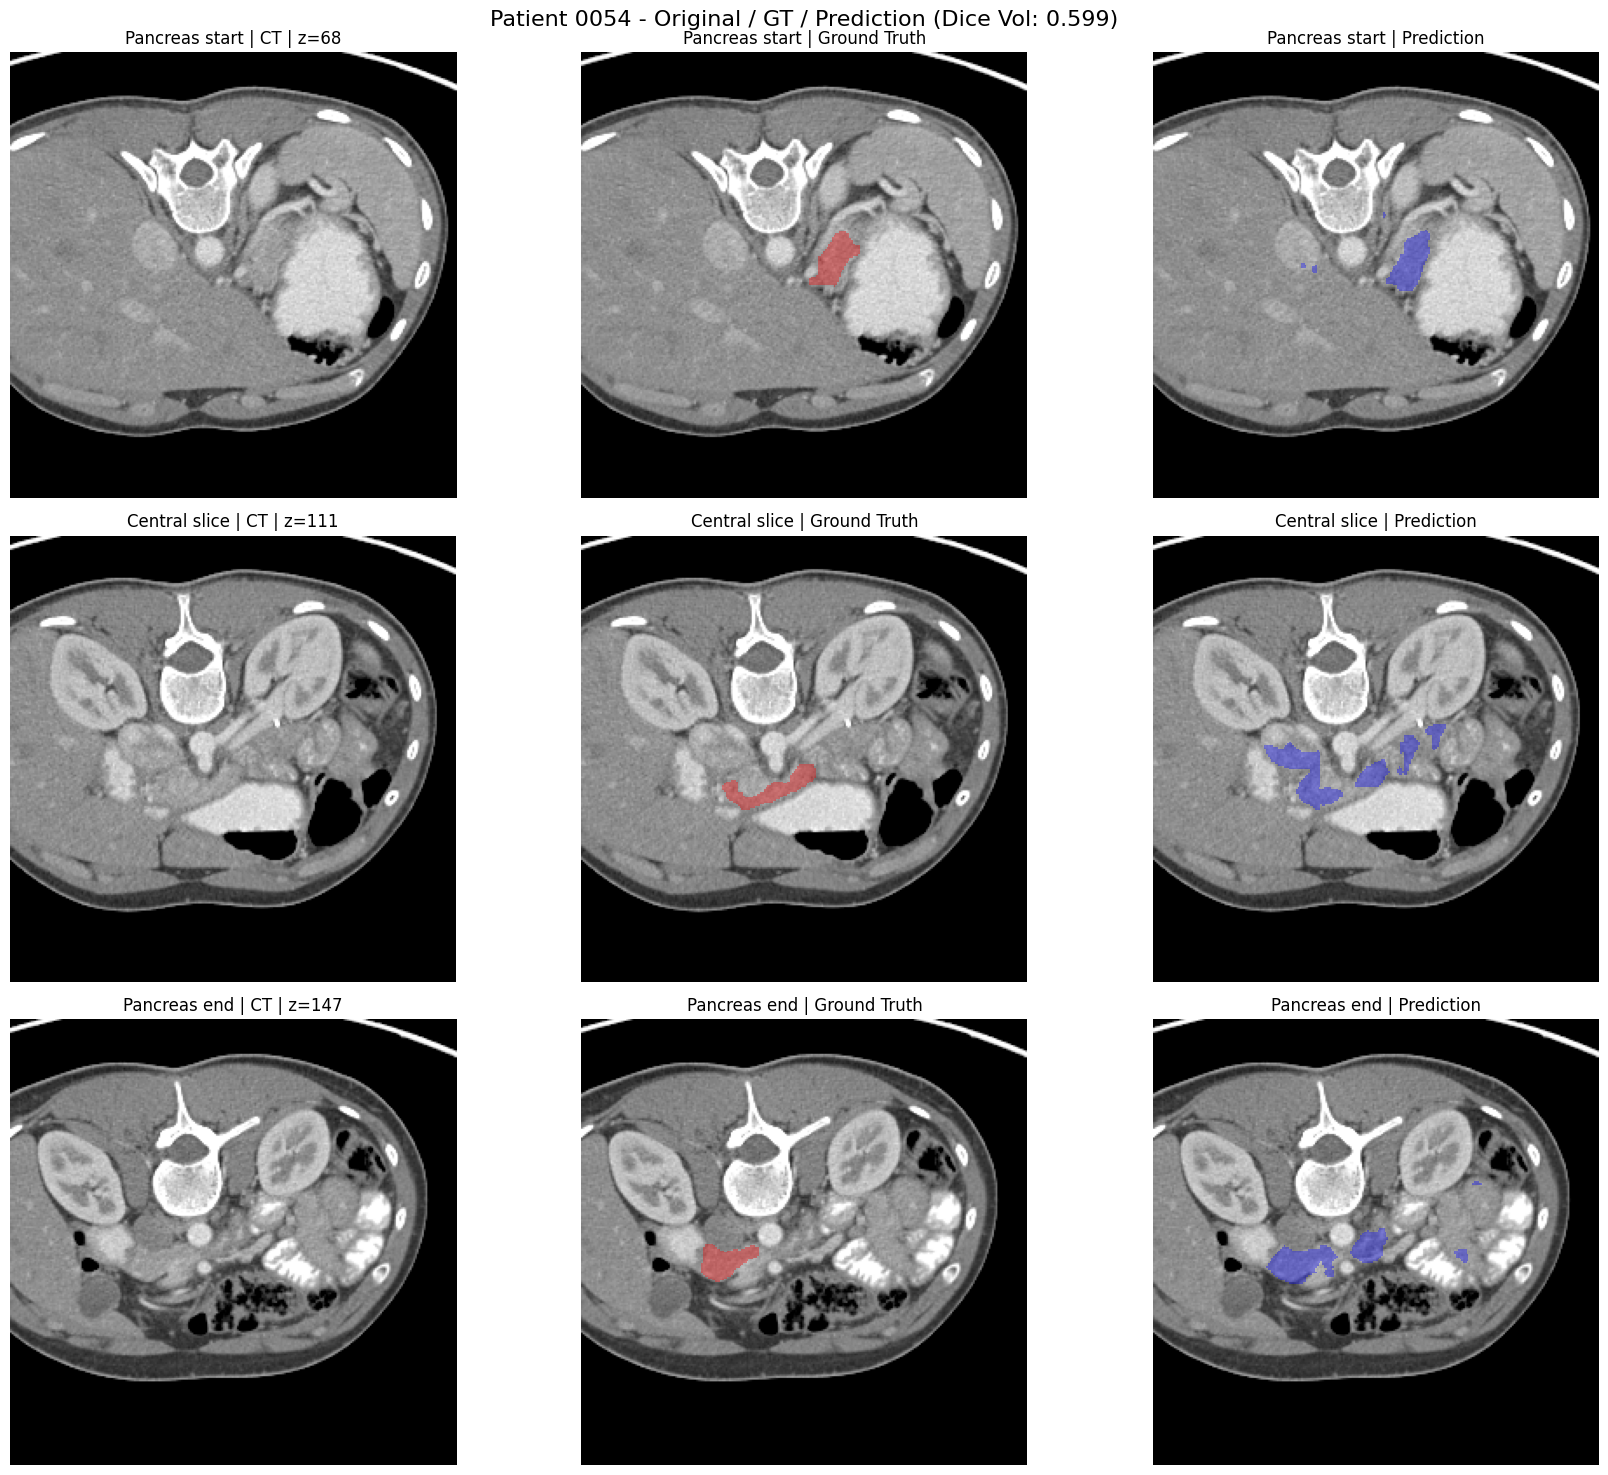

In [21]:
show_prediction_patient_3d_3slices_swin(
    model=model_swin,
    ct_dir=r"C:\Users\pietr\Desktop\Progetto ai\dataset_split_1303\test\ct",
    mask_dir=r"C:\Users\pietr\Desktop\Progetto ai\dataset_split_1303\test\mask",
    patient_id="0054",
    threshold=0.5,
    alpha=0.35,
    window=(-100, 200),
    device=device,
    area_ratio=0.20,
    roi_size=(96, 96, 96),
    sw_batch_size=1,
    overlap=0.5,
)

## **SECOND TRIAL**

In [22]:
import torch
from monai.networks.nets import SwinUNETR

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ckpt_path = r"C:\Users\pietr\Desktop\Visualizzazione otuput 3d\models 3d\second swinunetr\best_swinunetr_pancreas.pt"

model_swin_2 = SwinUNETR(
    in_channels=1,
    out_channels=1,
    feature_size=48,
    use_checkpoint=False,
).to(device)

model_swin_2.load_state_dict(torch.load(ckpt_path, map_location=device))
model_swin_2.eval()

print("Loaded SwinUNETR from:", ckpt_path)

Loaded SwinUNETR from: C:\Users\pietr\Desktop\Visualizzazione otuput 3d\models 3d\second swinunetr\best_swinunetr_pancreas.pt



Patient 0054
Selected slices: start=68, center=111, end=147
Pancreas range in GT: 62-159
Area threshold for start/end: 20% of max area
Volumetric Dice: 0.7418


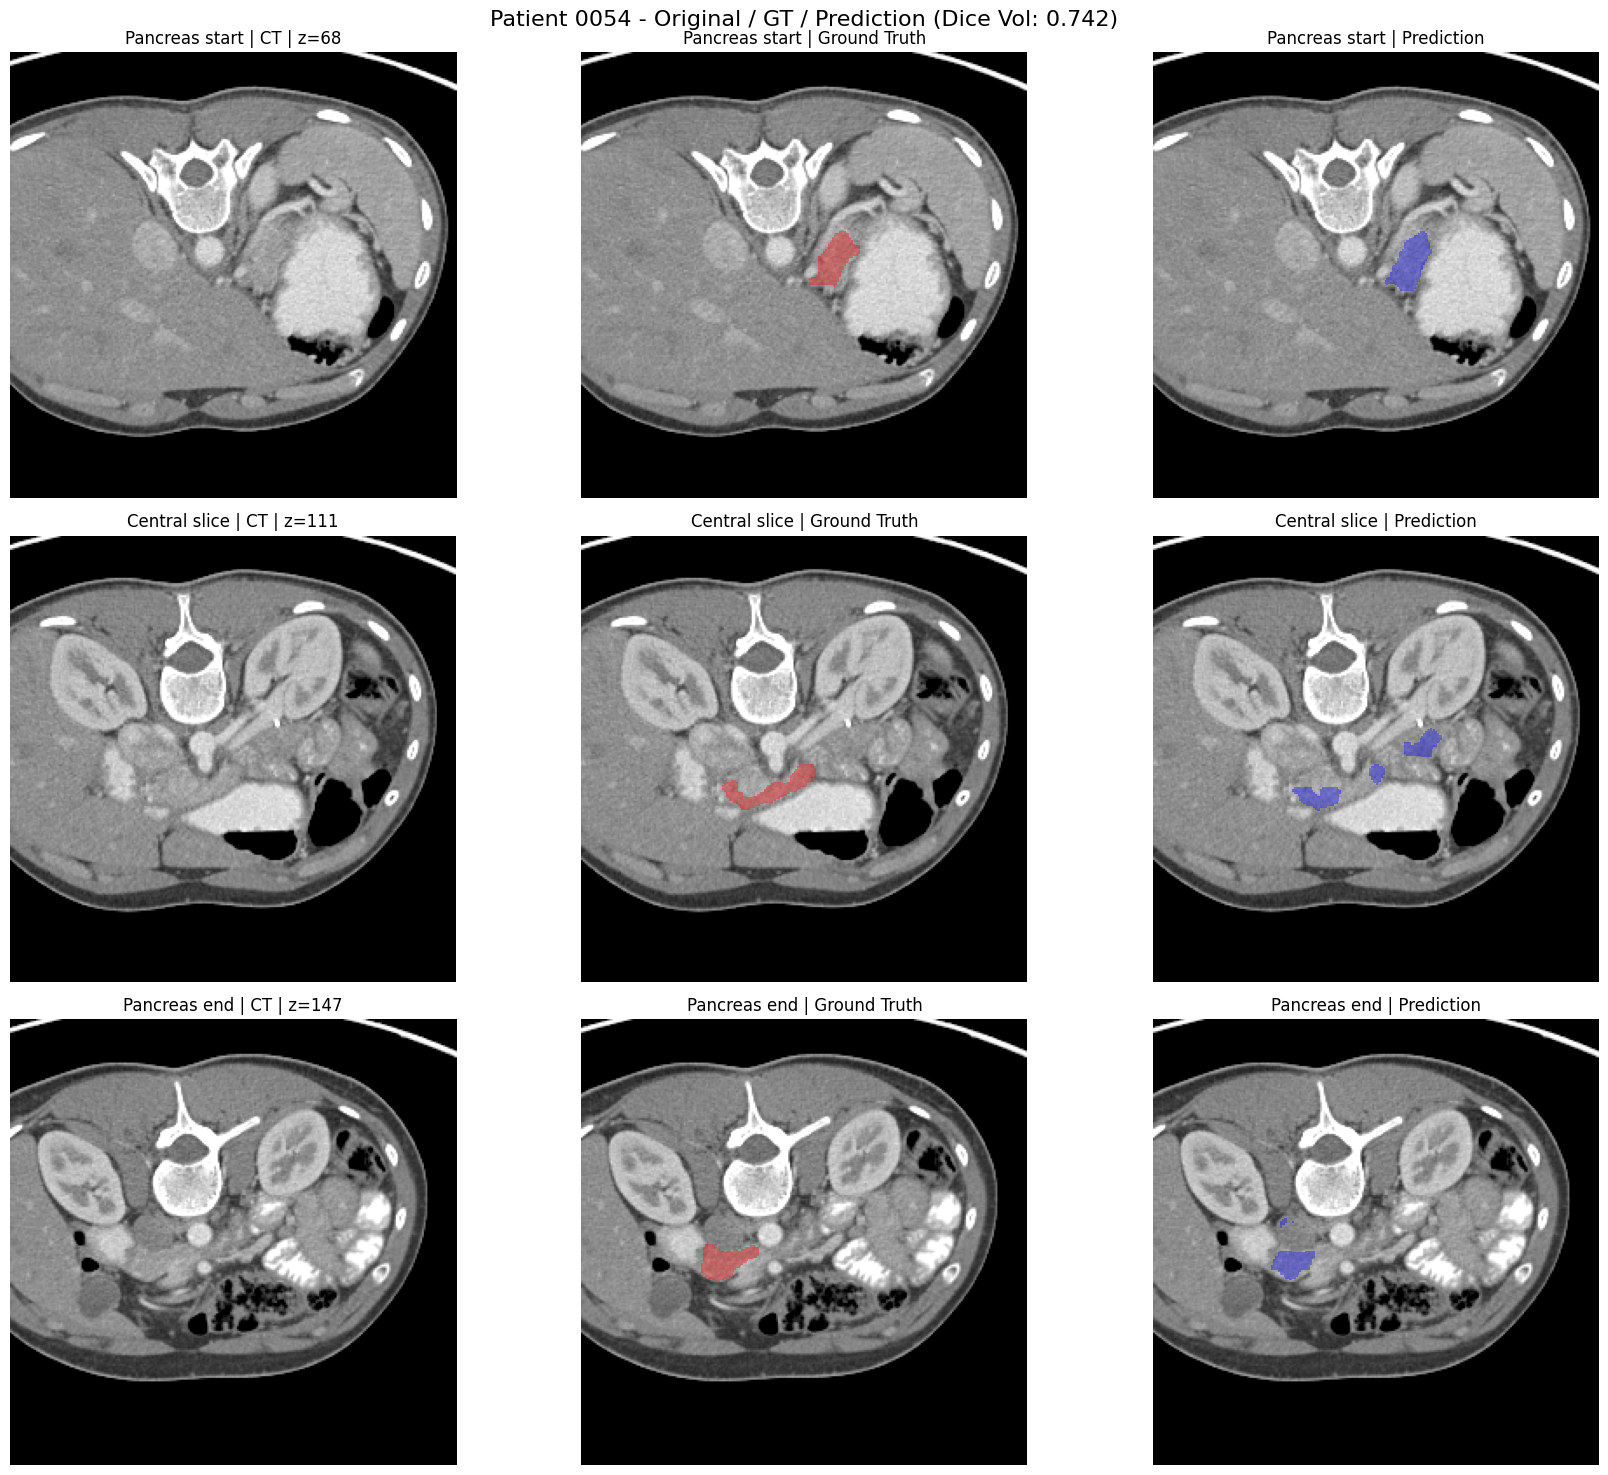

In [23]:
show_prediction_patient_3d_3slices_swin(
    model=model_swin_2,
    ct_dir=r"C:\Users\pietr\Desktop\Progetto ai\dataset_split_1303\test\ct",
    mask_dir=r"C:\Users\pietr\Desktop\Progetto ai\dataset_split_1303\test\mask",
    patient_id="0054",
    threshold=0.5,
    alpha=0.35,
    window=(-100, 200),
    device=device,
    area_ratio=0.20,
    roi_size=(96, 96, 96),
    sw_batch_size=1,
    overlap=0.5,
)